# Two-way ANOVA and interaction effects — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D017_05_two_way_anova_KEY.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# Two-Way ANOVA with `pingouin` — Instructor Notebook

## 1. Lesson Title
**Two-Way ANOVA Using the `pingouin` Library**

> This notebook contains the complete worked solutions. Use it for delivery and to mark student submissions.

## 2. Learning Outcomes

1. Explain what a **Two-Way ANOVA** is
2. Identify the dependent variable and two independent variables
3. Load and inspect a suitable dataset
4. Check important assumptions before running ANOVA
5. Run a Two-Way ANOVA using `pingouin`
6. Interpret main effects and the interaction effect
7. Perform post hoc tests after ANOVA
8. Write a short conclusion based on the results

## 3. Business / Real-World Scenario

A teacher wants to investigate whether **teaching method** and **study time** influence students' **test scores**.

- **Factor A:** `Teaching_Method` — Traditional, Interactive
- **Factor B:** `Study_Time` — Low, Medium, High
- **DV:** `Test_Score`

## 4. What is Two-Way ANOVA?

Tests three things at once:
1. main effect of **Factor A**
2. main effect of **Factor B**
3. **interaction effect** of A × B

## 5. Install Required Libraries

In [1]:
# !pip install pingouin pandas numpy scipy seaborn matplotlib statsmodels

In [ ]:
# ═══ CHECKPOINT — "Import Libraries" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

pass

print("Checkpoint restored. Ready for: Import Libraries")

## 6. Import Libraries

In [2]:
import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

## 7. Load the Dataset

Data is already prepared in `../data/teaching_method.csv`.

In [ ]:
# TODO: compute `df` from `Teaching_Method`, `Study_Time`
# Hint: pd.read_csv, .astype(), df.head
# Name your result: df

## 8. Understand the Structure of the Dataset

In [4]:
print('Shape:', df.shape)
print('\nFirst 5 rows:')
print(df.head())
print('\nTeaching_Method counts:')
print(df['Teaching_Method'].value_counts())
print('\nStudy_Time counts:')
print(df['Study_Time'].value_counts())

Shape: (120, 3)

First 5 rows:
  Teaching_Method Study_Time  Test_Score
0     Traditional        Low       58.43
1     Traditional        Low       52.11
2     Traditional        Low       60.53
3     Traditional        Low       61.42
4     Traditional        Low       47.83

Teaching_Method counts:
Teaching_Method
Interactive    60
Traditional    60
Name: count, dtype: int64

Study_Time counts:
Study_Time
High      40
Low       40
Medium    40
Name: count, dtype: int64


## 9. Descriptive Statistics

In [5]:
df.groupby(['Teaching_Method', 'Study_Time'], observed=True)['Test_Score'].agg(['mean', 'std', 'count'])

mean       std  count
Teaching_Method Study_Time                          
Interactive     High        85.4780  3.967292     20
                Low         63.5635  3.508204     20
                Medium      72.3355  3.417003     20
Traditional     High        72.5615  3.363863     20
                Low         56.8450  4.090597     20
                Medium      64.5145  3.738265     20

In [ ]:
# ═══ CHECKPOINT — "Visualize the Data" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('../../00-data/teaching_method.csv', index_col=0)
df['Teaching_Method'] = df['Teaching_Method'].astype('category')
df['Study_Time'] = df['Study_Time'].astype('category')

print("Checkpoint restored. Ready for: Visualize the Data")

## 10. Visualize the Data

### 10.1 Boxplot

In [ ]:
# TODO: draw a boxplot of `Study_Time`, split by `Teaching_Method`
# Hint: plt.figure, sns.boxplot, plt.title, plt.show

### 10.2 Interaction Plot

Parallel lines → little or no interaction. Crossing/diverging lines → interaction likely.

In [ ]:
# TODO: draw a interaction plot of `Study_Time`, split by `Teaching_Method`
# Hint: plt.figure, sns.pointplot, plt.title, plt.show
# Name your result: data, x, y, hue

## 11. Assumptions Before Running Two-Way ANOVA

1. continuous DV
2. categorical IVs
3. independent observations
4. no extreme outliers
5. normality within groups
6. homogeneity of variance

## 12. Check Variable Types

In [8]:
print(df.dtypes)

Teaching_Method    category
Study_Time         category
Test_Score          float64
dtype: object


## 13. Check for Potential Outliers

`|z| > 3` → investigate, do not auto-remove.

In [ ]:
# TODO: compute `outliers` from `z_score`, `Test_Score`
# Hint: stats.zscore, np.abs
# Name your result: outliers

In [ ]:
# ═══ CHECKPOINT — "Check Normality Within Each Group" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('../../00-data/teaching_method.csv', index_col=0)
df['Teaching_Method'] = df['Teaching_Method'].astype('category')
df['Study_Time'] = df['Study_Time'].astype('category')
df['z_score'] = stats.zscore(df['Test_Score'])
outliers = df[np.abs(df['z_score']) > 3]

print("Checkpoint restored. Ready for: Check Normality Within Each Group")

## 14. Check Normality Within Each Group

Shapiro-Wilk per cell of the design.
- H0: data is normally distributed
- p > 0.05 → normality not violated

In [ ]:
# TODO: compute `normality_summary`, `subset`, `result` from `Teaching_Method`, `Study_Time`, `Test_Score`
# Hint: pd.DataFrame, pg.normality, normality_summary.append
# Name your result: normality_summary, subset, result, normality_df

## 15. Q-Q Plot for Visual Normality Check

In [ ]:
# TODO: draw a `plt.figure` of `Teaching_Method`
# Hint: plt.figure, stats.probplot, plt.title, plt.show
# Name your result: subset

## 16. Check Homogeneity of Variance (Homoscedasticity)

Levene's test across all 6 cells.
- p > 0.05 → equal variances assumed

In [ ]:
# TODO: compute `levene_result`, `data`, `dv` from `Group`, `Teaching_Method`, `Study_Time`
# Hint: pg.homoscedasticity, .astype()
# Name your result: levene_result, data, dv, group

## 17. Run the Two-Way ANOVA

In [ ]:
# TODO: run an ANOVA, storing the result in `anova_results`
# Hint: pg.anova
# Name your result: anova_results, data, dv, between

In [ ]:
# ═══ CHECKPOINT — "How to Read the ANOVA Output" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('../../00-data/teaching_method.csv', index_col=0)
df['Teaching_Method'] = df['Teaching_Method'].astype('category')
df['Study_Time'] = df['Study_Time'].astype('category')
df['z_score'] = stats.zscore(df['Test_Score'])
outliers = df[np.abs(df['z_score']) > 3]
normality_summary = []
for method in df['Teaching_Method'].cat.categories:
    for study in df['Study_Time'].cat.categories:
        subset = df[(df['Teaching_Method'] == method) & (df['Study_Time'] == study)]['Test_Score']
        result = pg.normality(subset)
        normality_summary.append({'Teaching_Method': method, 'Study_Time': study, 'W': result['W'].values[0], 'p-value': result['pval'].values[0], 'Normal?': result['normal'].values[0]})
normality_df = pd.DataFrame(normality_summary)
for method in df['Teaching_Method'].cat.categories:
    for study in df['Study_Time'].cat.categories:
        subset = df[(df['Teaching_Method'] == method) & (df['Study_Time'] == study)]['Test_Score']
        plt.figure(figsize=(5, 4))
        stats.probplot(subset, dist='norm', plot=plt)
        plt.title(f'Q-Q Plot: {method} - {study}')
        plt.show()
df['Group'] = df['Teaching_Method'].astype(str) + '_' + df['Study_Time'].astype(str)
levene_result = pg.homoscedasticity(data=df, dv='Test_Score', group='Group', method='levene')
anova_results = pg.anova(data=df, dv='Test_Score', between=['Teaching_Method', 'Study_Time'], detailed=True)

print("Checkpoint restored. Ready for: How to Read the ANOVA Output")

## 18. How to Read the ANOVA Output

- `Source` → factor / interaction
- `SS`, `DF`, `MS`, `F`, `p_unc`, `np2` (effect size)

Focus on three rows:
1. `Teaching_Method` → main effect
2. `Study_Time` → main effect
3. `Teaching_Method * Study_Time` → interaction

## 19. Interpretation Template (Worked Example)

**Main Effect of Teaching Method**
> A two-way ANOVA showed a **statistically significant** main effect of teaching method on test score (`p-unc < .001`). On average, students in the Interactive group scored higher than those in the Traditional group.

**Main Effect of Study Time**
> There was also a **statistically significant** main effect of study time on test score (`p-unc < .001`), with average test scores increasing from Low → Medium → High study time.

**Interaction Effect**
> The interaction between teaching method and study time was **statistically significant** (`p-unc < .05`), indicating that the benefit of additional study time was larger for the Interactive method than for the Traditional method.

## 20. Post Hoc Test for `Study_Time`

3 levels → use Tukey HSD.

In [14]:
posthoc_study = pg.pairwise_tukey(
    data=df,
    dv='Test_Score',
    between='Study_Time'
)
posthoc_study

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,High,Low,79.01975,60.20425,18.81550,1.353153,13.904928,0.000000e+00,2.915820
1,High,Medium,79.01975,68.42500,10.59475,1.353153,7.829674,7.308931e-12,1.617692
2,Low,Medium,60.20425,68.42500,-8.22075,1.353153,-6.075254,4.745324e-08,-1.568241


## 21. Pairwise Comparison for `Teaching_Method`

Only 2 levels — Bonferroni-adjusted pairwise test.

In [15]:
posthoc_method = pg.pairwise_tests(
    data=df,
    dv='Test_Score',
    between='Teaching_Method',
    padjust='bonf'
)
posthoc_method

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p_unc,BF10,hedges
0,Teaching_Method,Interactive,Traditional,False,True,5.775243,118.0,two-sided,6.353477e-08,1.797e+05,1.047694


## 22. Explore Interaction Further: Simple Effects

### 22.1 Compare `Study_Time` within each `Teaching_Method`

In [ ]:
# TODO: compute `subset`, `result` from `Teaching_Method`
# Hint: pg.pairwise_tukey
# Name your result: subset, result

### 22.2 Compare `Teaching_Method` within each `Study_Time`

In [ ]:
# TODO: compute `subset`, `result`, `between` from `Study_Time`
# Hint: pg.pairwise_tests
# Name your result: subset, result, between

In [ ]:
# ═══ CHECKPOINT — "Optional: Pivot Table of Means" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('../../00-data/teaching_method.csv', index_col=0)
df['Teaching_Method'] = df['Teaching_Method'].astype('category')
df['Study_Time'] = df['Study_Time'].astype('category')
df['z_score'] = stats.zscore(df['Test_Score'])
outliers = df[np.abs(df['z_score']) > 3]
normality_summary = []
for method in df['Teaching_Method'].cat.categories:
    for study in df['Study_Time'].cat.categories:
        subset = df[(df['Teaching_Method'] == method) & (df['Study_Time'] == study)]['Test_Score']
        result = pg.normality(subset)
        normality_summary.append({'Teaching_Method': method, 'Study_Time': study, 'W': result['W'].values[0], 'p-value': result['pval'].values[0], 'Normal?': result['normal'].values[0]})
normality_df = pd.DataFrame(normality_summary)
for method in df['Teaching_Method'].cat.categories:
    for study in df['Study_Time'].cat.categories:
        subset = df[(df['Teaching_Method'] == method) & (df['Study_Time'] == study)]['Test_Score']
        plt.figure(figsize=(5, 4))
        stats.probplot(subset, dist='norm', plot=plt)
        plt.title(f'Q-Q Plot: {method} - {study}')
        plt.show()
df['Group'] = df['Teaching_Method'].astype(str) + '_' + df['Study_Time'].astype(str)
levene_result = pg.homoscedasticity(data=df, dv='Test_Score', group='Group', method='levene')
anova_results = pg.anova(data=df, dv='Test_Score', between=['Teaching_Method', 'Study_Time'], detailed=True)
posthoc_study = pg.pairwise_tukey(data=df, dv='Test_Score', between='Study_Time')
posthoc_method = pg.pairwise_tests(data=df, dv='Test_Score', between='Teaching_Method', padjust='bonf')
for method in df['Teaching_Method'].cat.categories:
    print(f'\nPost hoc Tukey for Study_Time within Teaching_Method = {method}')
    subset = df[df['Teaching_Method'] == method]
    result = pg.pairwise_tukey(data=subset, dv='Test_Score', between='Study_Time')
    print(result)
for study in df['Study_Time'].cat.categories:
    print(f'\nPairwise comparison for Teaching_Method within Study_Time = {study}')
    subset = df[df['Study_Time'] == study]
    result = pg.pairwise_tests(data=subset, dv='Test_Score', between='Teaching_Method', padjust='bonf')
    print(result)

print("Checkpoint restored. Ready for: Optional: Pivot Table of Means")

## 23. Optional: Pivot Table of Means

In [18]:
pivot_means = df.pivot_table(
    values='Test_Score',
    index='Study_Time',
    columns='Teaching_Method',
    aggfunc='mean',
    observed=True
)
pivot_means

Teaching_Method,Interactive,Traditional
Study_Time,,
High,85.4780,72.5615
Low,63.5635,56.8450
Medium,72.3355,64.5145


## 24. Student Exercise — Suggested Solution Outline

Apply the same workflow with `Exercise_Type` (Cardio, Strength) × `Sleep_Level` (Poor, Average, Good) → `Energy_Score`.

Reference template for live demonstration.

In [19]:
# Reference template — replace with the student's chosen dataset
# ex_df = pd.read_csv('your_exercise_data.csv')
# ex_df['Exercise_Type'] = ex_df['Exercise_Type'].astype('category')
# ex_df['Sleep_Level'] = ex_df['Sleep_Level'].astype('category')
#
# print(ex_df.groupby(['Exercise_Type', 'Sleep_Level'], observed=True)['Energy_Score']
#         .agg(['mean', 'std', 'count']))
#
# sns.boxplot(data=ex_df, x='Sleep_Level', y='Energy_Score', hue='Exercise_Type'); plt.show()
# sns.pointplot(data=ex_df, x='Sleep_Level', y='Energy_Score', hue='Exercise_Type',
#               dodge=True, markers=['o', 's'], capsize=0.1); plt.show()
#
# # Outliers
# ex_df['z'] = stats.zscore(ex_df['Energy_Score'])
# print(ex_df[np.abs(ex_df['z']) > 3])
#
# # Normality per cell
# for et in ex_df['Exercise_Type'].cat.categories:
#     for sl in ex_df['Sleep_Level'].cat.categories:
#         sub = ex_df[(ex_df['Exercise_Type'] == et) & (ex_df['Sleep_Level'] == sl)]['Energy_Score']
#         print(et, sl, pg.normality(sub))
#
# # Homogeneity of variance (combined group for Levene's test)
# ex_df['Group'] = ex_df['Exercise_Type'].astype(str) + '_' + ex_df['Sleep_Level'].astype(str)
# print(pg.homoscedasticity(data=ex_df, dv='Energy_Score',
#                            group='Group', method='levene'))
#
# # Two-way ANOVA
# print(pg.anova(data=ex_df, dv='Energy_Score',
#                between=['Exercise_Type', 'Sleep_Level'], detailed=True))
#
# # Post hoc on the 3-level factor
# print(pg.pairwise_tukey(data=ex_df, dv='Energy_Score', between='Sleep_Level'))
#
# # Pairwise on 2-level factor
# print(pg.pairwise_tests(data=ex_df, dv='Energy_Score',
#                          between='Exercise_Type', padjust='bonf'))

## 25. Reflection Questions — Model Answers

**1. What does the main effect of `Teaching_Method` mean?**
> It is the average difference in test scores between Traditional and Interactive teaching, **collapsed across all levels of study time**. It tells us whether teaching method matters overall, ignoring study time.

**2. What does the main effect of `Study_Time` mean?**
> It is the average difference in test scores across Low, Medium, and High study time, **collapsed across both teaching methods**. It tells us whether study time matters overall, ignoring teaching method.

**3. What does an interaction effect mean in this lesson?**
> It means that the effect of one factor **depends on** the level of the other. For example, additional study time may boost scores more under the Interactive method than under the Traditional method. Always inspect the interaction *first* — if it is significant, the main effects must be interpreted with caution.

**4. Why do we need post hoc tests?**
> A significant ANOVA tells us a difference exists somewhere, but not where. Post hoc tests (e.g. Tukey HSD) make all pairwise comparisons while controlling the family-wise error rate.

**5. Why do we check homogeneity of variance before ANOVA?**
> Standard ANOVA assumes equal variances across cells. Violating this — particularly with unbalanced sample sizes — inflates the Type I error rate. If violated, use Welch's correction or non-parametric alternatives.

## 26. Summary

Students learned to: load and inspect a 2 × 3 design, check assumptions, run Two-Way ANOVA, interpret main effects and the interaction, and explore simple effects with post hoc tests.

## Appendix — Full End-to-End Workflow Cell

Useful for live demonstration.

Descriptive statistics:
                               mean       std  count
Teaching_Method Study_Time                          
Interactive     High        85.4780  3.967292     20
                Low         63.5635  3.508204     20
                Medium      72.3355  3.417003     20
Traditional     High        72.5615  3.363863     20
                Low         56.8450  4.090597     20
                Medium      64.5145  3.738265     20


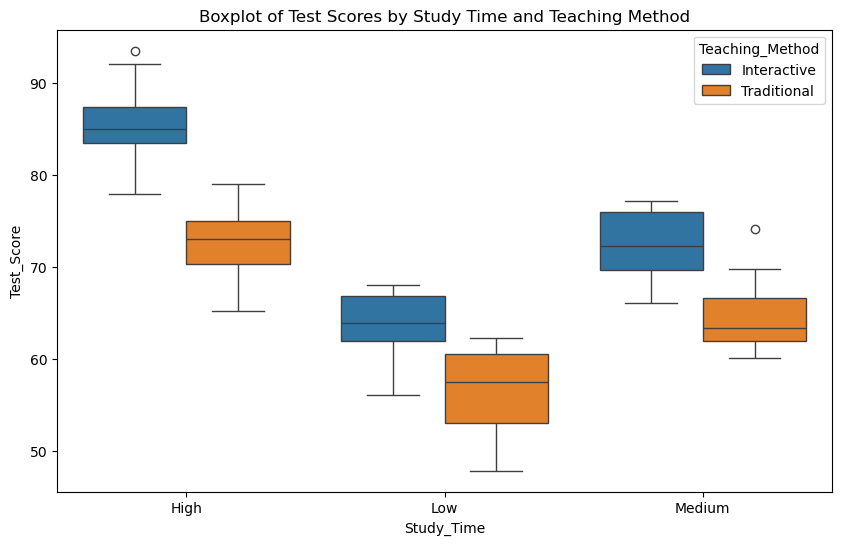

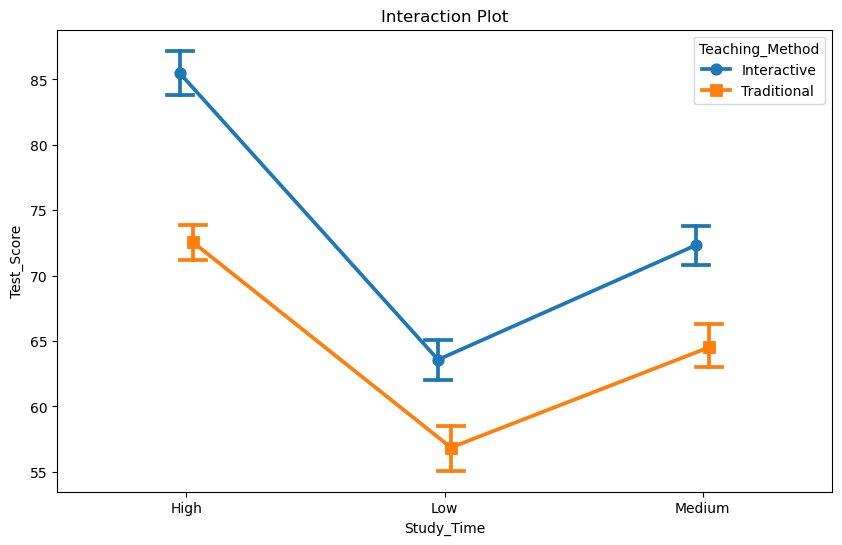


Potential outliers:
Empty DataFrame
Columns: [Teaching_Method, Study_Time, Test_Score, z_score]
Index: []

Normality:
  Teaching_Method Study_Time         W   p-value  Normal?
0     Interactive       High  0.984301  0.976982     True
1     Interactive        Low  0.931650  0.166123     True
2     Interactive     Medium  0.938694  0.226503     True
3     Traditional       High  0.983166  0.968160     True
4     Traditional        Low  0.934265  0.186466     True
5     Traditional     Medium  0.921117  0.104114     True

Levene:
               W      pval  equal_var
levene  0.208624  0.958267       True

ANOVA:


                         Source           SS   DF           MS           F  \
0               Teaching_Method  2512.773120    1  2512.773120  184.432749   
1                    Study_Time  7118.033312    2  3559.016656  261.225027   
2  Teaching_Method * Study_Time   218.649435    2   109.324717    8.024226   
3                      Residual  1553.173920  114    13.624333         NaN   

          p_unc       np2  
0  1.419325e-25  0.618004  
1  2.685405e-43  0.820881  
2  5.490110e-04  0.123404  
3           NaN       NaN  

Tukey post hoc — Study_Time:
      A       B    mean_A    mean_B      diff        se          T  \
0  High     Low  79.01975  60.20425  18.81550  1.353153  13.904928   
1  High  Medium  79.01975  68.42500  10.59475  1.353153   7.829674   
2   Low  Medium  60.20425  68.42500  -8.22075  1.353153  -6.075254   

        p_tukey    hedges  
0  0.000000e+00  2.915820  
1  7.308931e-12  1.617692  
2  4.745324e-08 -1.568241  

Pairwise — Teaching_Method:
          Contras

      A       B   mean_A   mean_B     diff        se          T       p_tukey  \
0  High     Low  85.4780  63.5635  21.9145  1.150693  19.044615  0.000000e+00   
1  High  Medium  85.4780  72.3355  13.1425  1.150693  11.421381  0.000000e+00   
2   Low  Medium  63.5635  72.3355  -8.7720  1.150693  -7.623234  8.708531e-10   

     hedges  
0  5.735732  
1  3.479214  
2 -2.482807  

Study_Time within Teaching_Method = Traditional
      A       B   mean_A   mean_B     diff        se          T       p_tukey  \
0  High     Low  72.5615  56.8450  15.7165  1.183542  13.279203  0.000000e+00   
1  High  Medium  72.5615  64.5145   8.0470  1.183542   6.799080  2.053676e-08   
2   Low  Medium  56.8450  64.5145  -7.6695  1.183542  -6.480122  6.944270e-08   

     hedges  
0  4.113394  
1  2.217980  
2 -1.918421  

Teaching_Method within Study_Time = High
          Contrast            A            B  Paired  Parametric          T  \
0  Teaching_Method  Interactive  Traditional   False        True  11

In [20]:
import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load data
df = pd.read_csv('../../00-data/teaching_method.csv', index_col=0)
df['Teaching_Method'] = df['Teaching_Method'].astype('category')
df['Study_Time'] = df['Study_Time'].astype('category')

print('Descriptive statistics:')
print(df.groupby(['Teaching_Method', 'Study_Time'], observed=True)['Test_Score']
        .agg(['mean', 'std', 'count']))

# 2. Visualizations
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Study_Time', y='Test_Score', hue='Teaching_Method')
plt.title('Boxplot of Test Scores by Study Time and Teaching Method')
plt.show()

plt.figure(figsize=(10, 6))
sns.pointplot(data=df, x='Study_Time', y='Test_Score', hue='Teaching_Method',
              dodge=True, markers=['o', 's'], capsize=0.1)
plt.title('Interaction Plot')
plt.show()

# 3. Outliers
df['z_score'] = stats.zscore(df['Test_Score'])
print('\nPotential outliers:')
print(df[np.abs(df['z_score']) > 3])

# 4. Normality per cell
rows = []
for method in df['Teaching_Method'].cat.categories:
    for study in df['Study_Time'].cat.categories:
        sub = df[(df['Teaching_Method'] == method) & (df['Study_Time'] == study)]['Test_Score']
        r = pg.normality(sub)
        rows.append({'Teaching_Method': method, 'Study_Time': study,
                     'W': r['W'].values[0], 'p-value': r['pval'].values[0],
                     'Normal?': r['normal'].values[0]})
print('\nNormality:')
print(pd.DataFrame(rows))

# 5. Homogeneity of variance (combined group for Levene's test)
df['Group'] = df['Teaching_Method'].astype(str) + '_' + df['Study_Time'].astype(str)
print('\nLevene:')
print(pg.homoscedasticity(data=df, dv='Test_Score',
                           group='Group', method='levene'))

# 6. Two-Way ANOVA
print('\nANOVA:')
print(pg.anova(data=df, dv='Test_Score',
                between=['Teaching_Method', 'Study_Time'], detailed=True))

# 7. Post hoc on Study_Time (3 levels)
print('\nTukey post hoc — Study_Time:')
print(pg.pairwise_tukey(data=df, dv='Test_Score', between='Study_Time'))

# 8. Pairwise on Teaching_Method (2 levels)
print('\nPairwise — Teaching_Method:')
print(pg.pairwise_tests(data=df, dv='Test_Score',
                         between='Teaching_Method', padjust='bonf'))

# 9. Simple effects
for method in df['Teaching_Method'].cat.categories:
    print(f'\nStudy_Time within Teaching_Method = {method}')
    sub = df[df['Teaching_Method'] == method]
    print(pg.pairwise_tukey(data=sub, dv='Test_Score', between='Study_Time'))

for study in df['Study_Time'].cat.categories:
    print(f'\nTeaching_Method within Study_Time = {study}')
    sub = df[df['Study_Time'] == study]
    print(pg.pairwise_tests(data=sub, dv='Test_Score',
                             between='Teaching_Method', padjust='bonf'))